<center><b>CTS2000: Scripting for the Humanities</b></center>
<center>8-1: TEI XML and Network Visualizations </center>

---

## TEI XML
TEI XML stands for *Text Encoding Initiative eXtensible Markup Language*. In short, it's a way to encode semantic information, i.e. information about meaning, into the text, so that it's easy to extract. 

This notebook uses `lxml`, which we didn't include in our environment at the start of the term. First, make sure you've selected the `cts2000` kernel (top right corner). Then run the cell below once to install `lxml`.

In [ ]:
%pip install lxml

### What is XML?

Imagine we have a list of two movies. And imagine each of those movies has certain properies. How could we make that data easily machine-readable? 

In XML, we could write it like this: 

```xml
<movies>
    <movie n="1">
      <title>Titanic</title>
      <director>James Cameron</director>
      <year>1997</year>
    </movie>
    <movie n="2">
      <title>Rain Man</title>
      <director>Barry Levinson</director>
      <year>1988</year>
    </movie>
</movies>
```

This is a hierarchical tree representing two movies and their associated properties.

Now, we can load this into a string, and parse it using a library like `xml`, like this:

In [26]:
xml = """<movies>
    <movie n="1">
      <title>Titanic</title>
      <director>James Cameron</director>
      <year>1997</year>
    </movie>
    <movie n="2">
      <title>Rain Man</title>
      <director>Barry Levinson</director>
      <year>1988</year>
    </movie>
</movies>
"""

In [27]:
# https://docs.python.org/3/library/xml.etree.elementtree.html
from xml.etree import ElementTree
tree = ElementTree.fromstring(xml)

Our string is now a **tree**. Each tag is a **node**: `<movies>` is the root, each `<movie>` is a child of the root, and `<title>`, `<director>` and `<year>` are children of a movie. The text, like *Titanic*, sits inside the nodes at the bottom.

<img src="../../img/movies_tree.png" alt="The movies XML as a tree" width="800">

In [28]:
tree.tag

'movies'

In [29]:
# tree is the root, <movies>. Looping over it gives us its children: each <movie>
for movie in tree:
    print(movie.tag, movie.attrib)

movie {'n': '1'}
movie {'n': '2'}


We can use the `find()` method to find a **node** in our tree. We first search for the first `movie` node, then within that scope, search for the first `title` node. We then use the `.text` attribute to get the text associated with that node, and print it.

In [30]:
first_movie = tree.find('movie')

# Then find and print the 'title' of the first movie
title = first_movie.find('title').text
print(title)

Titanic


### XML Tree

Adapted from [here](https://www.w3schools.com/xml/xml_tree.asp)

XML documents form a tree structure that starts at "the root" and branches to "the leaves".

![](../../img/nodetree.gif)

The tree looks like this in XML with more book entries

```xml
<?xml version="1.0" encoding="UTF-8"?>
<bookstore>
  <book category="cooking">
    <title lang="en">Everyday Italian</title>
    <author>Giada De Laurentiis</author>
    <year>2005</year>
    <price>30.00</price>
  </book>
  <book category="children">
    <title lang="en">Alice's Adventures in Wonderland</title>
    <author>Lewis Carroll</author>
    <year>1865</year>
    <price>12.99</price>
  </book>
  <book category="web">
    <title lang="en">Learning XML</title>
    <author>Erik T. Ray</author>
    <year>2003</year>
    <price>39.95</price>
  </book>
</bookstore>
```

### XML uses a self-describing syntax.

1. A prolog defines the XML version and the character encoding:
   
> ```xml
> <?xml version="1.0" encoding="UTF-8"?>
> ```

2. The next line is the root element of the document:

> ```xml
> <bookstore>
> ```

3. The next line starts a book element:
   
> ```xml
> <book category="cooking">
> ```


1. The book elements have 4 child elements: title, author, year, price.

> ```xml
> <title lang="en">Everyday Italian</title>
> <author>Giada De Laurentiis</author>
> <year>2005</year>
> <price>30.00</price>
> ```

5. The next line ends the book element:

> ```xml
> </book>
> ```

You can assume, from this example, that the XML document contains information about books in a bookstore.

### What about JSON?

XML is not the only way to make data machine-readable. Another very common format is **JSON** (JavaScript Object Notation). Here are the same two movies in JSON:

```json
{
  "movies": [
    {"n": 1, "title": "Titanic", "director": "James Cameron", "year": 1997},
    {"n": 2, "title": "Rain Man", "director": "Barry Levinson", "year": 1988}
  ]
}
```

If this looks familiar, that's because JSON looks almost exactly like Python: curly brackets `{}` are dictionaries, square brackets `[]` are lists.

In [5]:
import json

movies_json = """{
  "movies": [
    {"n": 1, "title": "Titanic", "director": "James Cameron", "year": 1997},
    {"n": 2, "title": "Rain Man", "director": "Barry Levinson", "year": 1988}
  ]
}"""

data = json.loads(movies_json)   # turn the JSON string into Python dictionaries and lists

# get the title of the first movie
data["movies"][0]["title"]

'Titanic'

Compare this with how we got the same title from XML: `tree.find('movie').find('title').text`. With JSON, we use the same square brackets we already use for dictionaries and lists.

### XML or JSON?

| | XML | JSON |
|---|---|---|
| Looks like | tags, like HTML | Python dictionaries and lists |
| Good at | **texts**: marking up words, lines and speeches inside a document | **data**: records with fields, like a table |
| Common in | scholarly editions (TEI), publishing | web APIs, data exchange |

This is why scholarly editions of plays use XML. In XML, markup can sit *inside* the text: a `<speaker>` tag, then the speech, with a `<stage>` direction in the middle of it. JSON is better at records with fields, which is why most web APIs send their answers in JSON. We already saw a bit of JSON in Wikidata API.

### What is TEI XML?

TEI XML is a certain brand of XML that can encode information about a text. `<said who="">` tags might encode who says a given line of dialogue, for instance. `<foreign lang="">` might tell us whether a given expression belongs to another language. All of this markup is useful to computational literary analysis. 

For an introduction, see [TEI By Example](http://teibyexample.org/). 

TEI XML files for literary texts may be found at [English Drama Corpus](https://dracor.org/eng), [The Folger Shakespeare Library](https://www.folgerdigitaltexts.org/download/), and [The Oxford Text Archive](http://ota.ox.ac.uk/catalogue/index.html). 


### Our text: *She Stoops to Conquer*

We'll work with Oliver Goldsmith's comedy [*She Stoops to Conquer* (1773)](https://en.wikipedia.org/wiki/She_Stoops_to_Conquer).

<div style="background: rgba(245, 180, 80, 0.15); border-left: 4px solid rgba(214, 140, 40, 0.9); border-radius: 6px; padding: 0.8em 1.2em; margin: 1.5em 0;">

<p><b>📖 The play in (hopefully) one minute</b></p>

<p>Mr. Hardcastle has invited young <b>Marlow</b>, the son of his old friend <b>Sir Charles</b>, to meet his daughter <b>Kate</b> (Miss Hardcastle) as a possible husband. But Marlow is shy with upper-class women and only at ease with women of lower status.</p>

<p>On the way, Marlow and his friend <b>Hastings</b> stop at an alehouse, where Kate's prankster stepbrother <b>Tony</b> tells them the Hardcastles' house is an inn. So Marlow treats Hardcastle like an innkeeper. Later, he mistakes Kate for a barmaid. Kate decides to keep up the disguise to see what he's really like and to gain his attention now that he is no longer too nervous to talk to her, i.e. she <i>stoops</i> to a lower role to <i>conquer</i> him.</p>

<p>Meanwhile, Hastings plans to run away with Kate's cousin <b>Constance</b> (Miss Neville), with Tony's help. In the last act, Sir Charles arrives, all the misunderstandings are cleared up, and Kate gets engaged to Marlow.</p>

</div>

The Oxford Text Archive edition of our text [*She Stoops to Conquer*](https://ota.bodleian.ox.ac.uk/repository/xmlui/handle/20.500.12024/K020903.000) was encoded in TEI XML by the Text Creation Partnership. We downloaded this XML file and it is in our data folder.

We are using an **edited** version of the file. The text of the play is exactly the same as in the original, but we made two changes to make it easier to analyse:

1. **We replaced the long s (ſ) with a regular s.** Eighteenth-century printers used ſ at the start and in the middle of words, so the original reads *Miſtakes* and *moſt*. To a computer, *moſt* and *most* are two different words.
2. **We standardized the speaker names.** In the original, names are written as they were printed: `Miſs HARDCASTLE.`, `TONY.`, and sometimes `TONY,`. We put them all in capitals and removed the punctuation, so they become `MISS HARDCASTLE` and `TONY`. Without this, Python would count `TONY.` and `TONY,` as two different characters.


The XML file can be found in the `../../data` folder of this repo. Let's open it using the `lxml` package (which allows us to manipulate xml-formatted data in Python) and see what we can do with it.

In [31]:
from lxml import etree
# https://lxml.de/

# Load the TEI XML file
with open('../../data/she_stoops_edit.xml', 'rb') as f:
    tree = etree.parse(f)
    
root = tree.getroot()

Let's unpack this:

`with open('../../data/she_stoops_edit.xml', 'rb') as f:` -> we open the file, just as we opened all our text files in this class. `with` makes sure Python closes the file again when we're done.

`'rb'` -> this is new. `'r'` means **read**, as before, and `'b'` means **binary**: Python gives us the raw bytes of the file instead of turning them into text first. Why? Look at the very first line of our XML file: `<?xml version='1.0' encoding='UTF-8'?>`. The file tells us its own encoding, so we let `lxml` read that line and decode the text itself, instead of Python guessing first.

`tree = etree.parse(f)` -> `lxml` reads the whole file and builds the tree out of it, like we did for the movies with `ElementTree.fromstring(xml)`. The difference: `fromstring` reads XML from a **string**, `parse` reads it from a **file**.

`root = tree.getroot()` -> `parse` gives us the **whole document**, which includes things like that first `<?xml ...?>` line. `getroot()` takes us to the top node of the tree, where everything else branches from. With the movies, `fromstring` gave us the root `<movies>` straight away, so we didn't need this step.

So which is the root of our play? Let's check:

In [17]:
root.tag # this is the top-level element

'{http://www.tei-c.org/ns/1.0}TEI'

Okie, this is a bit anti-climactic but there is a reason for it!

`'{http://www.tei-c.org/ns/1.0}TEI'`: the root is a `<TEI>` node. But what is the `{http://...}` in front of it? That's the TEI **namespace**, and we'll need it in a moment to search the tree.

In [18]:
for child in root: 
    print(child.tag)

{http://www.tei-c.org/ns/1.0}teiHeader
{http://www.tei-c.org/ns/1.0}text


The root has two children: `<teiHeader>`, with information *about* the text (title, author, who encoded it), and `<text>`, which contains the play itself.

### Using XPath to Navigate XML

When querying XML documents with `lxml`, we are using what is called ["XPath"](https://www.w3schools.com/xml/xml_xpath.asp). It is a query language that lxml (and other XML processing libraries) use to navigate and select specific parts of an XML document. First, we have to define a namespace mapping that the XPath engine will use to resolve the prefixes found in the XPath expression. 

We do this using a so-called URI (Uniform Resource Identifier). Note that, despite looking like a URL, in this context, the URI does not necessarily point to an actual location on the Internet. It doesn't need to retrieve anything from the web. The URI's goal is to provide a unique namespace identifier, not to be used as a network endpoint.

In [32]:
# Namespace map
ns = {'tei': 'http://www.tei-c.org/ns/1.0'}

Now, we can refer to this namespace when we navigate our XML file. We do so by adding a `namespace` attribute. 

In [33]:
title = root.find('.//tei:title', namespaces=ns)
title.text

'She stoops to conquer: or, the mistakes of a night. A comedy. As it is acted at the Theatre-Royal in Covent-Garden. Written by Doctor Goldsmith.'

We retrieved the title of the play. But what is this code doing? 

In the previous code cell, we are using XPath when defining `'.//tei:title'`. Here's what it means:

- `.:` This indicates that the search should start from the current node in the XML document tree (in this case, root).
- `//:` This signifies a search for the target node (tei:title) anywhere at or below the current node level in the document tree. It's a recursive descent from the current node, looking through all descendants.
- `tei:title:` This specifies the element name to look for. The prefix tei is associated with the namespace URI http://www.tei-c.org/ns/1.0 as defined in `ns`. This means the search is specifically for `title` elements that are within the TEI namespace.

When we use this XPath expression with the `find` method in lxml, it will search through the XML document starting from the root node, looking for the first occurrence of a `title` element that is in the TEI namespace. 

The `namespaces=ns` argument is crucial here because it defines the namespace prefixes used in the XPath expression, allowing lxml to correctly interpret `tei:title` as referring to http://www.tei-c.org/ns/1.0 title.

### What does the play look like in TEI?

Here is the beginning of Act 1, exactly as it appears in our file:

```xml
<div n="1" type="act">
   <head>ACT I.</head>
   <stage>SCENE, <hi>A</hi> CHAMBER <hi>in an old fashioned</hi> HOUSE. <hi>Enter</hi> Mrs. HARDCASTLE <hi>and</hi> Mr. HARDCASTLE.</stage>
   <sp>
      <speaker>MRS. HARDCASTLE</speaker>
      <p>I Vow, Mr. Hardcastle, you're very particular. Is there a creature in the whole country, but our<g ref="char:EOLhyphen"/>selves, that does not take a trip to town now and then, to rub off the rust a little? There's the two Miss Hoggs, and our neighbour, Mrs. Grigsby, go to take a month's polishing every winter.</p>
   </sp>
   <sp>
      <speaker>HARDCASTLE</speaker>
      <p>Ay, and bring back vanity and affectation to last them the whole year. I wonder why London cannot keep its own fools at home. In my time, the follies of the town crept slowly among us, but now they travel faster than a stage-coach. Its fopperies come down, not only as inside passengers, but in the very basket.</p>
   </sp>
   <sp>
      <pb n="2" facs="tcp:0387600800:8"/>
      <speaker>MRS. HARDCASTLE</speaker>
      <p>Ay, <hi>your</hi> times were fine times, indeed; you have been telling us of <hi>them</hi> for many a long year. Here we live in an old rumbling mansion, that looks for all the world like an inn, but that we never see compa<g ref="char:EOLhyphen"/>ny. [...]</p>
   </sp>
   <sp>
      <speaker>HARDCASTLE</speaker>
      <p>And I love it. I love every thing that's old: old friends, old times, old manners, old books, old wine; and, I believe, Dorothy, <stage>(taking her hand)</stage> you'll own I have been pretty fond of an old wife.</p>
   </sp>
   ...
</div>
```

The tags we'll use most:

| Tag | What it marks |
|---|---|
| `<div type="act">` | one act of the play. The attribute `n="1"` says which act |
| `<head>` | the heading, here *ACT I.* |
| `<stage>` | a stage direction. Notice it can appear between speeches **or inside one**, like *(taking her hand)* |
| `<sp>` | one speech: everything a character says before someone else speaks |
| `<speaker>` | the name of the character who speaks |
| `<p>` | the text of the speech |

You'll also see some tags that record details of the **printed book**:

- `<hi>` marks highlighted text, usually printed in italics.
- `<pb n="2"/>` marks a **page break**: page 2 of the original edition starts here, even in the middle of a speech.
- `<g ref="char:EOLhyphen"/>` marks a word that was **hyphenated at the end of a line** in print, like *our-selves*.

### Using text()

Note that XPath, like other programming languages, has functions. In the  following code cell we use the `text()` function,which grabs the text within the selected `speaker` node(s). 

Here's a snippet of the XML we have loaded:

<img src="../../img/xml-ex.png" alt="XML snippet" width="800"/>

In the following code, we use XPath the look for the `sp` nodes in our XML file, iterate over them, and print the text inside the `speaker` nodes using the `text()` function.

In [34]:
# all speeches in the play
speeches = tree.xpath('//tei:sp', namespaces=ns)
print(len(speeches), "speeches")

# the first one
first_sp = speeches[0]

print(first_sp.xpath('./tei:speaker', namespaces=ns))           # without text(): the node itself
print(first_sp.xpath('./tei:speaker/text()', namespaces=ns))    # with text(): the text inside it

841 speeches
[<Element {http://www.tei-c.org/ns/1.0}speaker at 0x19dcfba00>]
['MRS. HARDCASTLE']


Without `text()`, XPath gives us the `<speaker>` **node**, which Python shows as an `Element`. With `text()`, we get the text inside the node: *the name of the character*. Notice that both come back as a **list**, because `xpath()` always returns a list, even when there's only one match. That's why we'll write `[0]` to get the name out.

In [35]:
for sp in speeches[:10]:
    print(sp.xpath('./tei:speaker/text()', namespaces=ns)[0])

MRS. HARDCASTLE
HARDCASTLE
MRS. HARDCASTLE
HARDCASTLE
MRS. HARDCASTLE
HARDCASTLE
MRS. HARDCASTLE
HARDCASTLE
MRS. HARDCASTLE
HARDCASTLE


In [36]:
for sp in speeches[:10]:
    speaker = sp.xpath('./tei:speaker/text()', namespaces=ns)[0]
    speech = "".join(sp.xpath('./tei:p//text()', namespaces=ns))
    print(f"{speaker}: {speech[:100]}...")

MRS. HARDCASTLE: I Vow, Mr. Hardcastle, you're very particular. Is there a creature in the whole country, but ourselv...
HARDCASTLE: Ay, and bring back vanity and affectation to last them the whole year. I wonder why London cannot ke...
MRS. HARDCASTLE: Ay, your times were fine times, indeed; you have been telling us of them for many a long year. Here ...
HARDCASTLE: And I love it. I love every thing that's old: old friends, old times, old manners, old books, old wi...
MRS. HARDCASTLE: Lord, Mr. Hardcastle, you're for ever at your Dorothy's and your old wife's. You may be a Darby, but...
HARDCASTLE: Let me see; twenty added to twenty, makes just fifty and seven....
MRS. HARDCASTLE: It's false, Mr. Hardcastle: I was but twenty when I was brought to bed of Tony, that I had by Mr. Lu...
HARDCASTLE: Nor ever will, I dare answer for him. Ay, you have taught him finely....
MRS. HARDCASTLE: No matter, Tony Lumpkin has a good fortune. My son is not to live by his learning. I don't think a b...

Notice the double slash in `./tei:p//text()`

In [37]:
third_sp = speeches[2]

print("".join(third_sp.xpath('./tei:p/text()', namespaces=ns))[:80])    # one slash
print("".join(third_sp.xpath('./tei:p//text()', namespaces=ns))[:80])   # two slashes

Ay,  times were fine times, indeed; you have been telling us of  for many a long
Ay, your times were fine times, indeed; you have been telling us of them for man


With one slash, text() only takes the text directly inside `<p>`. The words your and them are inside `<hi>` tags (they were printed in italics), so they disappear. With two slashes, //text() takes the text inside `<p>` and inside everything within it.

Now let's do something more complicated. In the following code, we iterate through our `sp` nodes, looking for speakers, and getting their associated dialogue, which we save in a list.

In [38]:
# Initialize a list to hold dialogues along with speakers
dialogues_with_speakers = []

# Iterate through <sp> elements to extract dialogue and associated speaker
for sp in tree.xpath('//tei:sp', namespaces=ns):
    # Extract speaker name; assume there is only one <speaker> per <sp>
    speaker = sp.xpath('./tei:speaker/text()', namespaces=ns)[0]
    # Extract dialogue content: all text within <sp>, except the <speaker> and any <stage> directions
    dialogue_content = "".join(sp.xpath('.//text()[not(ancestor::tei:speaker)][not(ancestor::tei:stage)]', namespaces=ns))
    # Tidy up the spaces and line breaks left over from the XML
    dialogue_content = " ".join(dialogue_content.split())
    # Append to our list
    dialogues_with_speakers.append((speaker, dialogue_content))

# Example output for verification
for speaker, dialogue in dialogues_with_speakers[:5]:  # Just show the first 5 for brevity
    print(f"Speaker: {speaker}, Dialogue: {dialogue[:100]}...")  # Show first 100 characters of dialogue

Speaker: MRS. HARDCASTLE, Dialogue: I Vow, Mr. Hardcastle, you're very particular. Is there a creature in the whole country, but ourselv...
Speaker: HARDCASTLE, Dialogue: Ay, and bring back vanity and affectation to last them the whole year. I wonder why London cannot ke...
Speaker: MRS. HARDCASTLE, Dialogue: Ay, your times were fine times, indeed; you have been telling us of them for many a long year. Here ...
Speaker: HARDCASTLE, Dialogue: And I love it. I love every thing that's old: old friends, old times, old manners, old books, old wi...
Speaker: MRS. HARDCASTLE, Dialogue: Lord, Mr. Hardcastle, you're for ever at your Dorothy's and your old wife's. You may be a Darby, but...


Let's unpack this:

This cell goes through every speech (`<sp>`) in the play and saves two things: **who** speaks and **what** they say. But not all the text inside a speech is spoken. Remember the excerpt from Act 1: the speaker's name is inside the `<sp>`, and so are stage directions like *(taking her hand)*. We want to leave both out.

`speaker = sp.xpath('./tei:speaker/text()', namespaces=ns)[0]` -> the name of the character, as before. `[0]` takes it out of the list that `xpath()` always returns.

`.//text()` -> all the text inside the speech, at any level: inside `<p>`, inside `<hi>`, inside the lines of a song.

`[not(ancestor::tei:speaker)]` -> but not the text inside `<speaker>`, because that's the name, not the speech.

`[not(ancestor::tei:stage)]` -> and not the text inside `<stage>`, because stage directions aren't spoken. When we write two conditions in a row, `[...][...]`, the text has to meet **both**.

`ancestor::` -> checks every node **above** the text: its parent, its parent's parent, and so on, up to the root. We use it instead of `parent::`, which only checks the node directly above. That matters when a tag sits inside another one. In one speech, the stage direction is `<stage><hi>(To</hi> Tony.)</stage>`: the parent of *(To* is `<hi>`, not `<stage>`, so `parent::` would miss it and *(To* would end up in the dialogue.

`" ".join(dialogue_content.split())` -> removing stage directions can leave behind gaps of spaces and line breaks from the XML file. `.split()` breaks the text into words at every run of spaces or line breaks, and `" ".join()` glues them back together with single spaces.

Why not just take the text inside each `<p>`? Because some speeches also contain **songs**, which are encoded as lines of verse in `<lg>` and `<l>` tags, not in `<p>`. If we only took `<p>`, we would silently lose the songs. So instead we take everything, and remove what we don't want.

We can now use this data in order to calculate how many dialogues each speaker engages in, as well as the average length of words that each speaker uses.

### defaultdict

Documentation: https://docs.python.org/3/library/collections.html#collections.defaultdict

`defaultdict` is a subclass of `dict` or dictionaries that returns a default value when a key is not found. It is useful for counting occurrences or grouping items without needing to check if the key exists first. If the key is not found, it will return the default value specified during initialization. For example, if you initialize it with `int` as in `defaultdict(int)`, the value is automatically 0.

In [39]:
from collections import defaultdict

# Initialize dictionaries for counts and lengths
dialogue_counts = defaultdict(int)
dialogue_lengths = defaultdict(list)

for speaker, dialogue in dialogues_with_speakers:
    # Count dialogues
    dialogue_counts[speaker] += 1
    # Measure dialogue length in words and store
    dialogue_lengths[speaker].append(len(dialogue.split()))

# For analysis, calculate average lengths
average_lengths = {speaker: sum(lengths)/len(lengths) for speaker, lengths in dialogue_lengths.items()}

# Print dialogue counts and average lengths, from most to fewest speeches
for speaker in sorted(dialogue_counts, key=dialogue_counts.get, reverse=True):
    print(f"{speaker}: {dialogue_counts[speaker]} dialogues, Average length: {average_lengths[speaker]:.2f} words")


MARLOW: 161 dialogues, Average length: 24.58 words
HARDCASTLE: 135 dialogues, Average length: 26.34 words
HASTINGS: 116 dialogues, Average length: 20.00 words
TONY: 109 dialogues, Average length: 28.35 words
MISS HARDCASTLE: 108 dialogues, Average length: 24.16 words
MRS. HARDCASTLE: 85 dialogues, Average length: 27.48 words
MISS NEVILLE: 54 dialogues, Average length: 24.98 words
SIR CHARLES: 21 dialogues, Average length: 14.52 words
DIGGORY: 10 dialogues, Average length: 18.60 words
LANDLORD: 8 dialogues, Average length: 16.62 words
SERVANT: 8 dialogues, Average length: 17.75 words
MAID: 6 dialogues, Average length: 16.17 words
OMNES: 5 dialogues, Average length: 3.00 words
SECOND FELLOW: 3 dialogues, Average length: 35.33 words
FIRST FELLOW: 2 dialogues, Average length: 12.00 words
THIRD FELLOW: 2 dialogues, Average length: 30.00 words
FIRST SERVANT: 2 dialogues, Average length: 5.50 words
SECOND SERVANT: 2 dialogues, Average length: 11.50 words
FOURTH FELLOW: 1 dialogues, Average le

Before we look at who talks to whom, let's see **when** each character speaks. We'll make a list of all the speakers in the order they speak, then plot it.

In [40]:
# Extracting speakers, in the order they speak
speakers = [speaker for speaker, _ in dialogues_with_speakers]

# should be same as the begining of act 1
speakers[:10]

['MRS. HARDCASTLE',
 'HARDCASTLE',
 'MRS. HARDCASTLE',
 'HARDCASTLE',
 'MRS. HARDCASTLE',
 'HARDCASTLE',
 'MRS. HARDCASTLE',
 'HARDCASTLE',
 'MRS. HARDCASTLE',
 'HARDCASTLE']

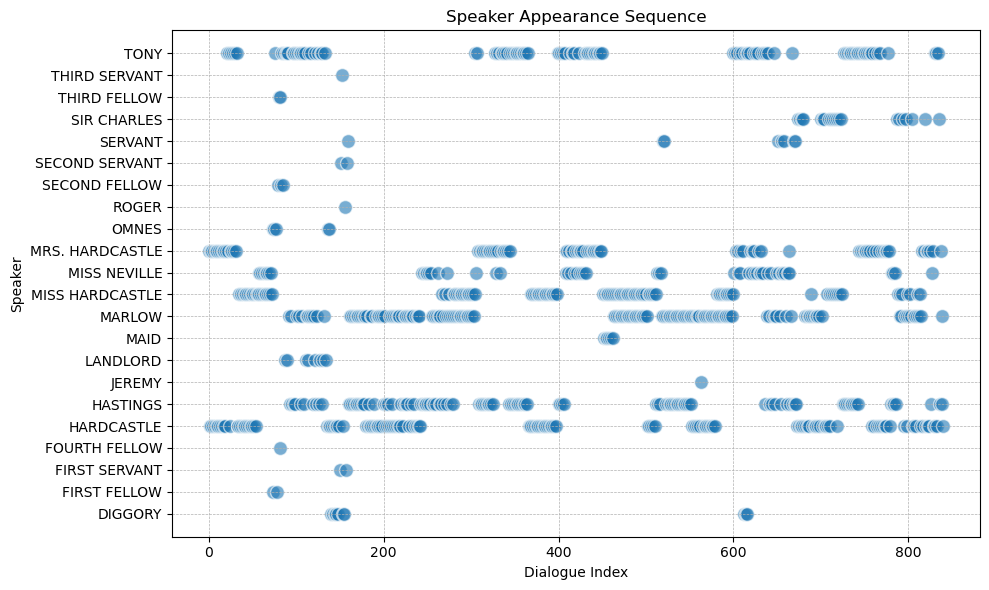

In [41]:
import matplotlib.pyplot as plt

# Provided 'speakers' list with the sequence of speaker appearances

# Map speaker names to unique integers for plotting
speaker_ids = {name: i for i, name in enumerate(sorted(set(speakers)))}
# Inverse mapping for y-axis labels
id_to_speaker = {i: name for name, i in speaker_ids.items()}

# Prepare data for plotting
x = list(range(len(speakers)))  # Dialogue indices
y = [speaker_ids[name] for name in speakers]  # Mapped speaker IDs

# Plotting
plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.6, edgecolors='w', s=100)  # Adjust size (s) and transparency (alpha) as needed

plt.xlabel('Dialogue Index')
plt.ylabel('Speaker')
plt.title('Speaker Appearance Sequence')
plt.yticks(list(id_to_speaker.keys()), list(id_to_speaker.values()))  # Set custom y-axis labels

plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()



### Once we have characters and dialogues, we can create a network visualization

First, we need to map interactions. We'll say that two characters **interact** or have a **dialogue** when one speaks right after the other in the same act. This is a heuristic and it is not perfect. But it works reasonably well for a comedy like this, where most scenes are two or three characters talking back and forth. Some issues with this are:
- Group scenes. In a scene with four characters, A might speak to C, but if B happens to speak between them, we count A → B and B → C instead.
- Asides. The play has stage directions like (Apart to Tony). The character speaks to one person, but we connect them to whoever speaks next.
- People who don’t answer. If Hardcastle speaks to Miss Hardcastle when she enters, but she leaves without replying, we never count it.
- Content. We only count the order of speeches, not whether they’re actually talking to each other.

Two things to watch out for:

- **Acts.** The last speaker of Act 1 doesn't talk to the first speaker of Act 2, so we count interactions **one act at a time**. This is where the TEI structure helps: each act is a `<div type="act">`.
- **Talking to yourself.** Sometimes the same character has two speeches in a row, with a stage direction in between, usually someone entering. We don't count that as an interaction.

In [42]:
# Initialize counters for interactions
interactions = defaultdict(lambda: defaultdict(int))

# Count who speaks after whom, one act at a time
for act in tree.xpath('//tei:div[@type="act"]', namespaces=ns):
    act_speakers = [sp.xpath('./tei:speaker/text()', namespaces=ns)[0]
                    for sp in act.xpath('.//tei:sp', namespaces=ns)]

    for current_speaker, next_speaker in zip(act_speakers, act_speakers[1:]):
        if current_speaker != next_speaker:          # no talking to yourself
            interactions[current_speaker][next_speaker] += 1


In [43]:
# We can create a function that prints interactions in a more readable format for a specific character
def print_interactions_for_character(character):
    print(f"Interactions for {character}:")
    for interlocutor, count in interactions[character].items():
        print(f"  Talks to {interlocutor}: {count} times")
    print("\n")

# Print interactions for Miss Hardcastle
print_interactions_for_character("MISS HARDCASTLE")

Interactions for MISS HARDCASTLE:
  Talks to HARDCASTLE: 32 times
  Talks to MISS NEVILLE: 8 times
  Talks to OMNES: 1 times
  Talks to MARLOW: 49 times
  Talks to TONY: 3 times
  Talks to MAID: 6 times
  Talks to SIR CHARLES: 6 times
  Talks to HASTINGS: 1 times




In [44]:
# Print interactions for Miss Hardcastle
print_interactions_for_character("HARDCASTLE")

Interactions for HARDCASTLE:
  Talks to MRS. HARDCASTLE: 21 times
  Talks to MISS HARDCASTLE: 33 times
  Talks to OMNES: 2 times
  Talks to DIGGORY: 6 times
  Talks to FIRST SERVANT: 1 times
  Talks to MARLOW: 44 times
  Talks to HASTINGS: 8 times
  Talks to JEREMY: 1 times
  Talks to SIR CHARLES: 9 times
  Talks to TONY: 6 times




In [46]:
# How much of Miss Hardcastle's talk is with Marlow, compared to everyone else?
with_marlow = interactions["MISS HARDCASTLE"]["MARLOW"]
with_everyone = sum(interactions["MISS HARDCASTLE"].values())

print(f"Miss Hardcastle's interactions in total: {with_everyone}")
print(f"With Marlow: {with_marlow} ({with_marlow / with_everyone:.2%})")


Miss Hardcastle's interactions in total: 106
With Marlow: 49 (46.23%)


In [47]:
# We can also visualize interactions using a heatmap
import pandas as pd
import plotly.express as px

# Create a DataFrame from the interactions dictionary
# columns: who speaks, rows: who speaks next
interaction_matrix = pd.DataFrame(interactions).fillna(0).astype(int)

fig = px.imshow(
    interaction_matrix,
    text_auto=True,                          # write the number in each cell
    color_continuous_scale="Blues",
    aspect="auto",
    labels=dict(x="speaker", y="speaks next", color="interactions"),
    title="Character Interaction Heatmap",
)
fig.update_xaxes(tickangle=45, tickmode="array", tickvals=interaction_matrix.columns, ticktext=interaction_matrix.columns)
fig.update_yaxes(tickmode="array", tickvals=interaction_matrix.index, ticktext=interaction_matrix.index)
fig.update_layout(height=800)
fig.show()


In [48]:
# Get the top 10 characters by total interactions (sum of rows + columns)
interaction_sums = interaction_matrix.sum(axis=1) + interaction_matrix.sum(axis=0)
top_10 = interaction_sums.sort_values(ascending=False).head(10).index

# Filter the interaction matrix to only include these top 10 characters
top10_matrix = interaction_matrix.loc[top_10, top_10]

fig = px.imshow(
    top10_matrix,
    text_auto=True,
    color_continuous_scale="Blues",
    aspect="auto",
    labels=dict(x="speaker", y="speaks next", color="interactions"),
    title="Character Interaction Heatmap (Top 10 Characters)",
)
fig.update_xaxes(tickangle=45)
fig.update_layout(height=600)
fig.show()


## 

## What is a network?

A **network** (also called a **graph**) is a way of showing how things are connected. It has two parts:

- **Nodes**: the things themselves. In our network, each node is a **character**.
- **Edges**: the connections between them. In our network, an edge means two characters **interact**: one speaks right after the other.

Edges can also have a **weight**: a number that says how strong the connection is. Our weights are the number of times two characters interact. Marlow and Miss Hardcastle, who talk to each other a lot, get a heavy edge. Two characters who exchange a single line get a light one.

### Directed or undirected?

Networks come in two kinds:

- In a **directed** network, edges have a direction, like an arrow: A → B is not the same as B → A. Think of Twitter, where you can follow someone without them following you back.
- In an **undirected** network, an edge simply connects two nodes, in both directions at once. Think of Facebook friends: if you're friends with someone, they're friends with you.

Our `interactions` dictionary is directed: it counts Marlow → Miss Hardcastle and Miss Hardcastle → Marlow separately. But we saw that these two numbers are almost always the same, because characters take turns in a conversation. So we'll build an **undirected** network, and add both directions together into one edge.

### Reading a network

Two things to keep in mind when we draw it:

- **The degree** of a node is the number of edges it has: how many different characters someone talks to. With weights, we can also count *how much* they talk in total.
- **Positions don't mean much on their own.** Python places the nodes using a **layout** algorithm that tries to keep connected nodes close together and spread the rest out. Being near each other usually means two characters are connected, but there is no north or south, and a different layout can draw the same network very differently.

We'll use the `networkx` library to build the network and `matplotlib` to draw it.

In [49]:
import networkx as nx
import matplotlib.pyplot as plt

# 'interactions' counts each direction separately (A -> B and B -> A).
# Our network is undirected, so we add both directions together into one edge.

G = nx.Graph()

for speaker, others in interactions.items():
    for other, count in others.items():
        if G.has_edge(speaker, other):
            G[speaker][other]["weight"] += count     # the other direction is already there: add to it
        else:
            G.add_edge(speaker, other, weight=count)

G["MARLOW"]["MISS HARDCASTLE"]


{'weight': 98}

`G["MARLOW"]["MISS HARDCASTLE"]` looks up the **edge** between two nodes. Python shows us the edge's attributes as a dictionary: here, a `weight` of 98. That's the 49 times Marlow speaks right before Miss Hardcastle, plus the 49 times she speaks right before him, added together into one edge.

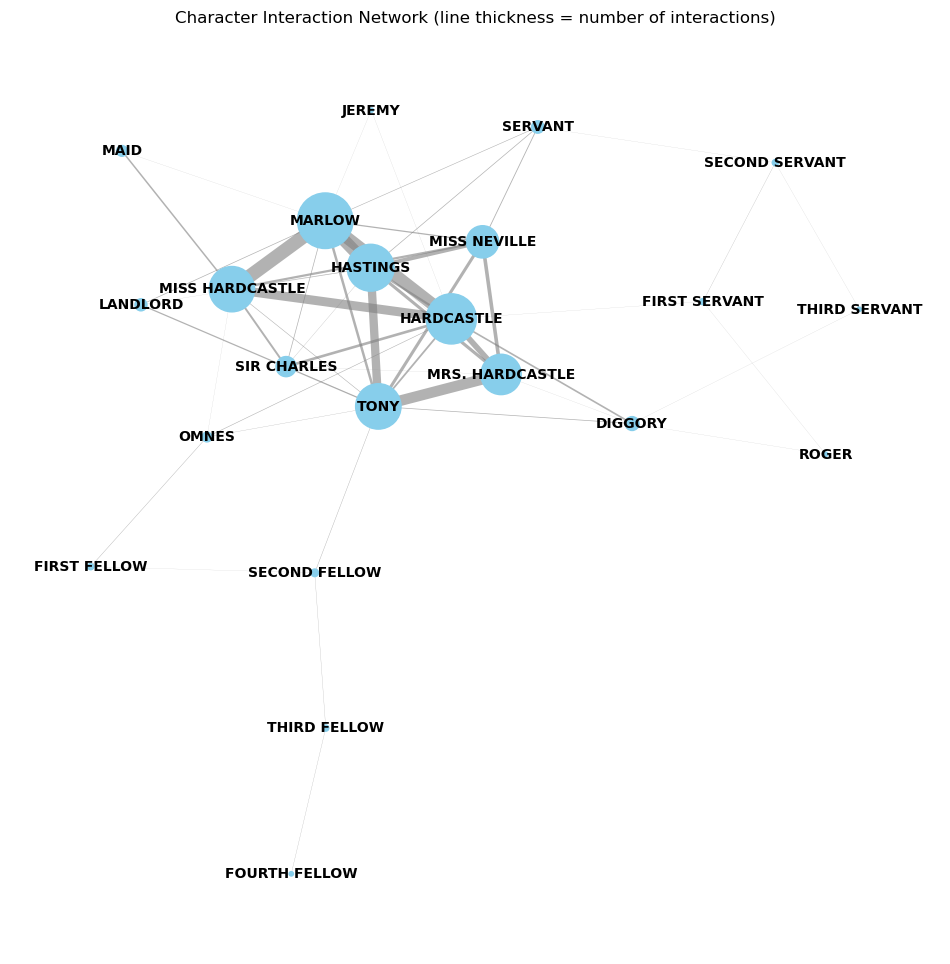

In [50]:
plt.figure(figsize=(12, 12))
pos = nx.kamada_kawai_layout(G, weight=None)   # weight=None: Kamada-Kawai would treat weights as distances

interaction_totals = dict(G.degree(weight="weight"))   # all interactions for each character

nx.draw_networkx_nodes(G, pos, node_size=[interaction_totals[n] * 5 for n in G.nodes()], node_color="skyblue")
nx.draw_networkx_edges(G, pos, width=[G[u][v]["weight"] / 10 for u, v in G.edges()], edge_color="gray", alpha=0.6)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

plt.title("Character Interaction Network (line thickness = number of interactions)")
plt.axis("off")
plt.show()


### Reading our first network

This network already shows us a lot. **Marlow** has the biggest node: he interacts more than anyone else. The thickest line connects him to **Miss Hardcastle**, the couple at the centre of the plot. Around the edges, we see characters who only exchange a few lines with one or two others, like the servants and the fellows at the alehouse.

We made two **design choices** here: node size shows how much a character interacts in total, and line thickness shows how often two characters interact. Notice that both size and thickness tell us something different.

But the drawing also has problems:

- The labels sit **on top of** the nodes and lines, and in the crowded centre they overlap.
- All the nodes are the **same colour**, so colour doesn't tell us anything.
- There is no explanation on the chart itself of what size and thickness mean, except for a long title.

### A second try: a different layout and colour

Let's try two changes. We'll use a different **layout**, `spring_layout`, which imagines every edge as a spring that pulls connected nodes together. And we'll **colour** each node by its **degree**: the number of different characters it is connected to.

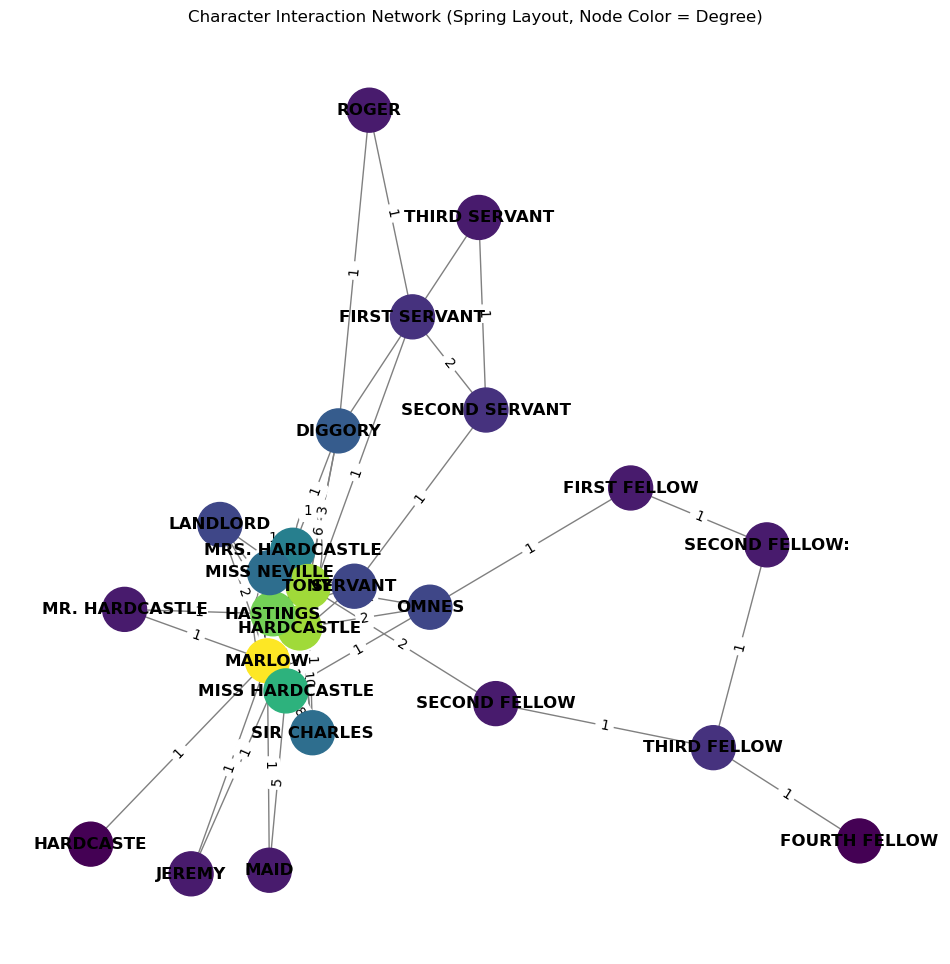

In [25]:
plt.figure(figsize=(12, 12))
pos = nx.spring_layout(G, seed=42)  # Spring layout for force-directed placement

# Color nodes by degree (number of connections)
degrees = dict(G.degree())
node_colors = [degrees[n] for n in G.nodes()]

nx.draw_networkx(
    G, pos,
    node_size=1000,
    node_color=node_colors,
    cmap=plt.cm.viridis,
    with_labels=True,
    font_weight="bold",
    edge_color="gray"
)

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("Character Interaction Network (Spring Layout, Node Color = Degree)")
plt.axis('off')
plt.show()

### What changed?

Is this better? Not really, and it's worth seeing why.

- **The layout:** `spring_layout` uses the weights by default, so the strongest edges are the strongest springs. The main characters, who all talk to each other a lot, get pulled into a tight clump in the middle, where we can't read them.
- **The colour:** the title tells us that colour shows **degree**, but colour and size now show almost the same thing: how connected a character is. The characters with big nodes are also the ones with bright colours, so we are using two visual features to say one thing. And without a colour bar, we still can't tell which colour means "many connections" and which means "few".
- **The numbers on the edges:** with more than 50 edges, the labels pile on top of each other and hide the network.

💡 A good rule for any visualization: **every visual feature should tell the reader something different**, and the reader should be able to tell what it is. Position, size, thickness, colour, labels: each one is a chance to show something.

### Take Three

Let's use what we've learned from the first two. We keep what worked: the Kamada-Kawai layout, node size for how much a character interacts, and line thickness for how often two characters interact. Then we fix the rest:

- **Colour** now shows something new: which **group** a character belongs to in the play. We have to decide the groups ourselves, in a dictionary.
- **Labels** go below the nodes, with a white background so we can read them over the lines. Main characters get bold labels, minor ones small grey labels.
- A **legend** explains the colours, and a **subtitle** explains size and thickness.

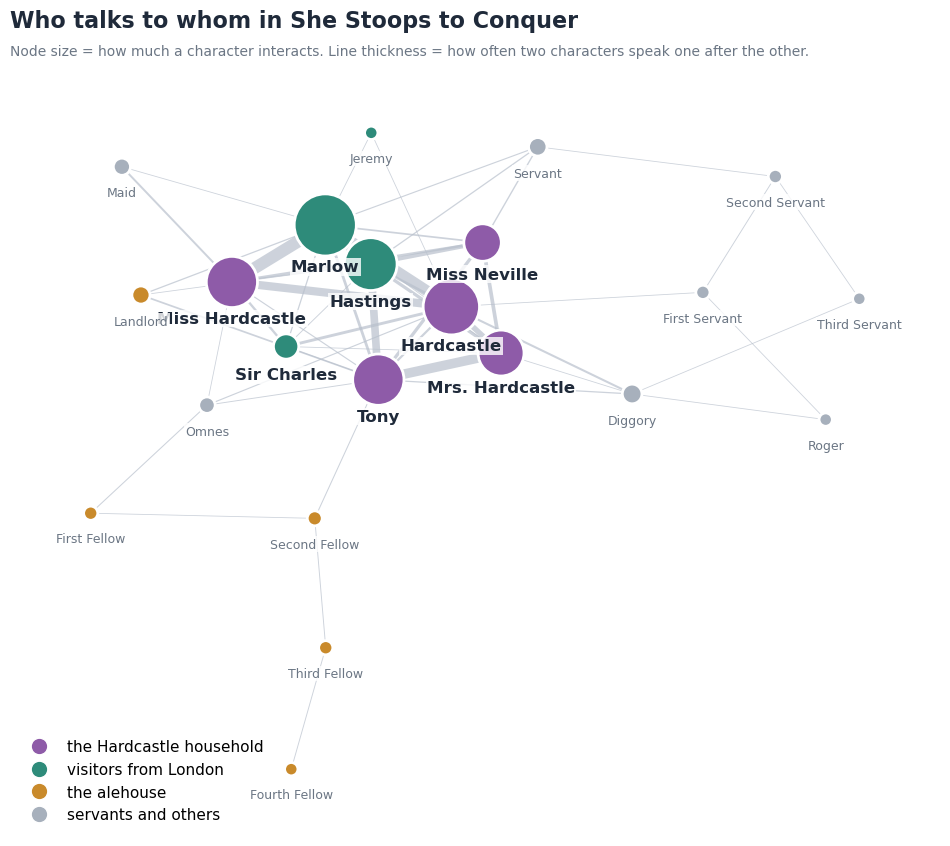

In [51]:
from matplotlib.lines import Line2D

# group the characters, so we can colour them
groups = {
    "HARDCASTLE": "the Hardcastle household", "MRS. HARDCASTLE": "the Hardcastle household",
    "MISS HARDCASTLE": "the Hardcastle household", "TONY": "the Hardcastle household",
    "MISS NEVILLE": "the Hardcastle household",
    "MARLOW": "visitors from London", "HASTINGS": "visitors from London",
    "SIR CHARLES": "visitors from London", "JEREMY": "visitors from London",
    "LANDLORD": "the alehouse", "FIRST FELLOW": "the alehouse", "SECOND FELLOW": "the alehouse",
    "THIRD FELLOW": "the alehouse", "FOURTH FELLOW": "the alehouse",
}
group_colors = {
    "the Hardcastle household": "#8E5BA8",
    "visitors from London": "#2E8B7A",
    "the alehouse": "#C98A2B",
    "servants and others": "#A7B0BC",
}
# anyone not in our dictionary counts as "servants and others"
node_colors = [group_colors[groups.get(n, "servants and others")] for n in G.nodes()]

pos = nx.kamada_kawai_layout(G, weight=None)
totals = dict(G.degree(weight="weight"))     # all interactions for each character

fig, ax = plt.subplots(figsize=(12, 10))

# edges: thicker = more interactions
nx.draw_networkx_edges(G, pos, ax=ax,
    width=[0.5 + G[u][v]["weight"] / 12 for u, v in G.edges()],
    edge_color="#B8C0CC", alpha=0.7)

# nodes: bigger = more interactions
nx.draw_networkx_nodes(G, pos, ax=ax,
    node_size=[80 + totals[n] * 6 for n in G.nodes()],
    node_color=node_colors, edgecolors="white", linewidths=2)

# labels below each node: bold for the main characters, small and grey for everyone else
main = [n for n in G.nodes() if totals[n] >= 40]
minor = [n for n in G.nodes() if totals[n] < 40]
label_pos = {n: (x, y - 0.045 - totals[n] / 9000) for n, (x, y) in pos.items()}
label_box = dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1)

nx.draw_networkx_labels(G, label_pos, labels={n: n.title() for n in main}, ax=ax,
    font_size=12, font_weight="bold", font_color="#1F2A3A", verticalalignment="top", bbox=label_box)
nx.draw_networkx_labels(G, label_pos, labels={n: n.title() for n in minor}, ax=ax,
    font_size=9, font_color="#6B7684", verticalalignment="top", bbox=label_box)

# legend for the colours
legend = [Line2D([0], [0], marker="o", color="white", markerfacecolor=c, markersize=12, label=g)
          for g, c in group_colors.items()]
ax.legend(handles=legend, loc="lower left", frameon=False, fontsize=11)

ax.set_title("Who talks to whom in She Stoops to Conquer", loc="left",
             fontsize=16, fontweight="bold", color="#1F2A3A", pad=28)
ax.text(0, 1.01, "Node size = how much a character interacts. Line thickness = how often two characters speak one after the other.",
        transform=ax.transAxes, fontsize=10, color="#6B7684", va="bottom")
ax.axis("off")
plt.show()

Now the structure of the play is visible at a glance: the Hardcastle household and the visitors from London in the middle, the drinkers at the alehouse trailing off at the bottom, and the servants around the edges.

⚠️ Remember that the groups are **our** decision, not something in the XML. Miss Neville is Mrs. Hardcastle's niece, so we put her in the household. Jeremy is Marlow's servant, so we put him with the visitors from London. Would you group anyone differently?

### How does the network change over the play?

So far, we've drawn the whole play as one network. But a play happens in time: characters arrive, leave, and meet in different combinations. Since our XML marks each act as a `<div type="act">`, we can draw one network **per act**.

This time, we make two new design choices:

- **We only show the main cast.** Eight characters have at least 40 interactions in the play, and everyone else has 20 or fewer. When we draw all 22, the minor characters spread out around the edges and squeeze the main cast into the middle, exactly where the interesting connections are. Below each act, we note how many minor characters we left out.
- **We put the main cast on a circle.** Each character keeps the **same position** in every act, so we can compare the five drawings. The household sits on one side of the circle and the visitors from London on the other.

Characters who don't speak in an act stay on the circle as small grey dots, with grey names, so we can also see who is **missing**.

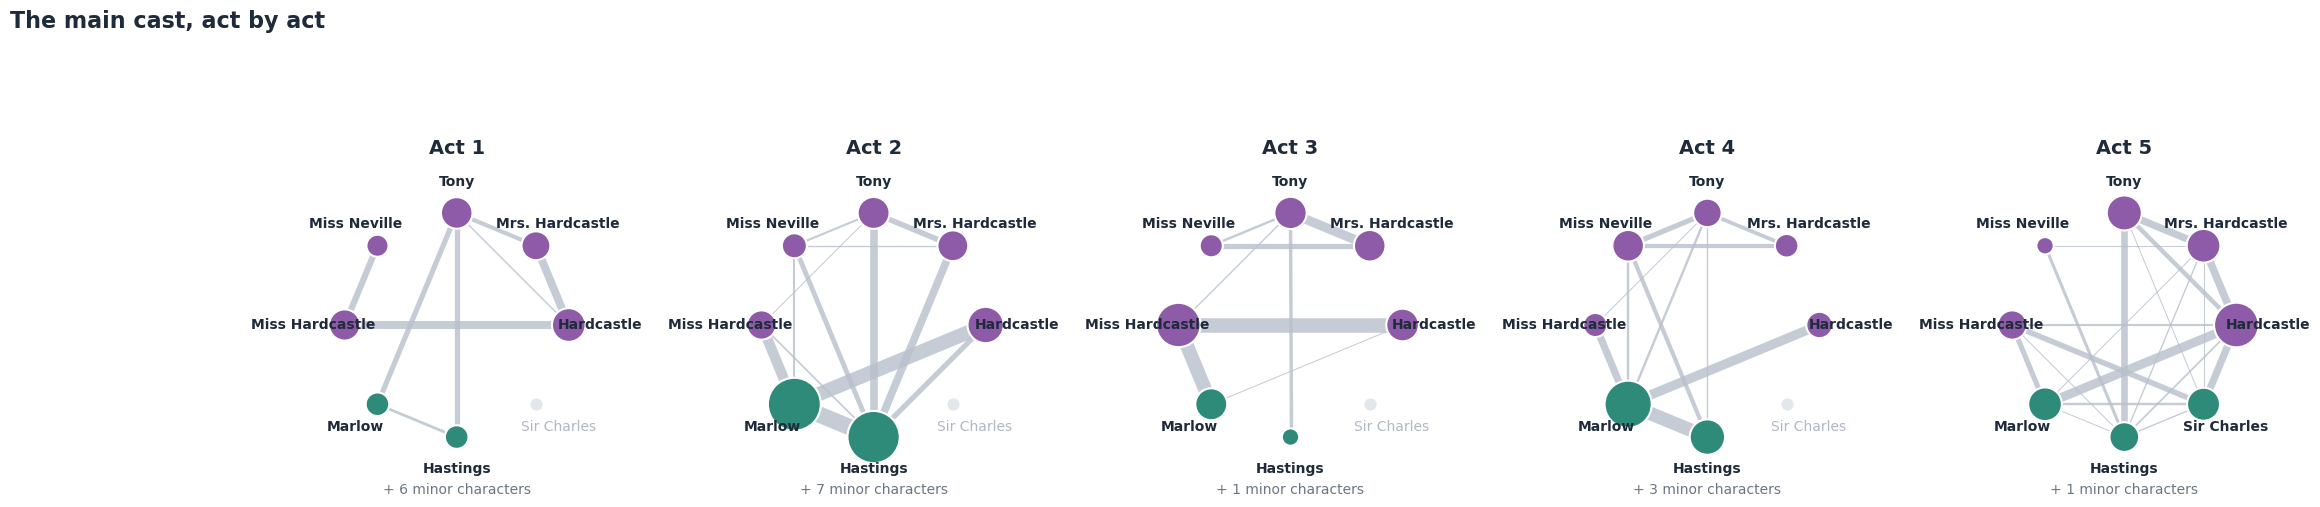

In [54]:
# the main cast: everyone with at least 40 interactions in the whole play
# we put them on a circle, the household first and then the visitors, so the groups sit together
main_cast = ["HARDCASTLE", "MRS. HARDCASTLE", "TONY", "MISS NEVILLE", "MISS HARDCASTLE",
             "MARLOW", "HASTINGS", "SIR CHARLES"]
circle_pos = nx.circular_layout(main_cast)

acts = tree.xpath('//tei:div[@type="act"]', namespaces=ns)
fig, axes = plt.subplots(1, 5, figsize=(26, 6.5))

for act_number, (act, ax) in enumerate(zip(acts, axes), start=1):
    # build a small network for this act, as before
    act_speakers = [sp.xpath('./tei:speaker/text()', namespaces=ns)[0]
                    for sp in act.xpath('.//tei:sp', namespaces=ns)]
    G_act = nx.Graph()
    for current_speaker, next_speaker in zip(act_speakers, act_speakers[1:]):
        if current_speaker != next_speaker:
            if G_act.has_edge(current_speaker, next_speaker):
                G_act[current_speaker][next_speaker]["weight"] += 1
            else:
                G_act.add_edge(current_speaker, next_speaker, weight=1)

    # keep only the main cast, and count how many minor characters we left out
    G_main = G_act.subgraph([n for n in G_act.nodes() if n in main_cast])
    act_totals = dict(G_main.degree(weight="weight"))
    others = len([n for n in G_act.nodes() if n not in main_cast])

    # everyone in the main cast as a small grey dot, then this act's network on top
    nx.draw_networkx_nodes(nx.Graph(), circle_pos, nodelist=main_cast, ax=ax, node_size=60, node_color="#E3E7EC")
    nx.draw_networkx_edges(G_main, circle_pos, ax=ax,
        width=[0.5 + G_main[u][v]["weight"] / 4 for u, v in G_main.edges()],
        edge_color="#B8C0CC", alpha=0.8)
    nx.draw_networkx_nodes(G_main, circle_pos, ax=ax,
        node_size=[60 + act_totals[n] * 12 for n in G_main.nodes()],
        node_color=[group_colors[groups[n]] for n in G_main.nodes()],
        edgecolors="white", linewidths=1.5)

    # labels outside the circle: dark if the character speaks in this act, light grey if not
    for n in main_cast:
        x, y = circle_pos[n]
        speaks = n in G_main
        ax.text(x * 1.28, y * 1.28, n.title(), ha="center", va="center", fontsize=10,
                fontweight="bold" if speaks else "normal",
                color="#1F2A3A" if speaks else "#B0B8C3")

    ax.set_title(f"Act {act_number}", fontsize=14, fontweight="bold", color="#1F2A3A")
    ax.text(0.5, -0.02, f"+ {others} minor characters", transform=ax.transAxes,
            ha="center", fontsize=10, color="#6B7684")
    ax.set_xlim(-1.55, 1.55)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect("equal")     # keep the circle round
    ax.axis("off")

fig.suptitle("The main cast, act by act", x=0.02, ha="left", fontsize=16, fontweight="bold", color="#1F2A3A")
plt.show()

Before we close off this discussion of networks, please note that networks aren’t just images, we can measure them too. One interesting measure is betweenness.

**Betweenness** measures how often a character sits on the shortest path between two other characters. A character with high betweenness is a **bridge**: without them, parts of the network would not be connected. Who has the highest betweenness? Does that match their role in the plot?

In [55]:
# betweenness: how often a character sits on the shortest path between two other characters
betweenness = nx.betweenness_centrality(G)
sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:5]

[('TONY', 0.34645794681508973),
 ('SECOND FELLOW', 0.19812409812409812),
 ('HARDCASTLE', 0.1950419157562015),
 ('DIGGORY', 0.14308390022675738),
 ('MARLOW', 0.13441300762729336)]

Tony came out on top, well ahead of everyone else, even though Marlow has the most interactions. Betweenness measures who connects parts of the network that would otherwise be apart, and Tony is the only link between the alehouse and the household. That’s also his role in the plot: he’s the one who tricks Marlow and Hastings into thinking the Hardcastles’ house is an inn.